# 02 · Stepwise decomposition regression (paper Table 2)

> **Paper** &nbsp; I-Cheng Yeh and Tzu-Kuang Hsu (2018), "Building real estate
> valuation models with comparative approach through case-based reasoning",
> *Applied Soft Computing* **65**, 260-271.
> [doi:10.1016/j.asoc.2018.01.029](https://doi.org/10.1016/j.asoc.2018.01.029)
>
> **Data** &nbsp; UCI Machine Learning Repository, *Real Estate Valuation*
> ([doi:10.24432/C5J30W](https://doi.org/10.24432/C5J30W)), CC BY 4.0 — the
> Sindian circle of supply and demand, 414 transactions.

---

## The idea

The paper assumes a price per unit area is the circle's average price scaled by a product of dimensionless **adjustment coefficients**, one per factor (Eq. 9):

$$Y_j = \bar{Y}\,k_{1j}k_{2j}\cdots k_{mj}$$

Each $k$ answers: *how much does this one feature push this property above or below the typical property in its market?* A coefficient of 1.1 means +10%.

The coefficients cannot be observed, only their product $k_j = Y_j/\bar{Y}$ (Eq. 10). The paper separates them **greedily**: attribute the whole product to the most important factor, fit a curve, divide it out, attribute the remainder to the next factor, and so on (Eqs. 12, 16, 19, 21). The geographic coordinate is taken last, because the sorting quantile method cannot score a two-component factor.

This is a **multiplicative** analogue of forward stagewise regression. The order matters, and the paper names optimising it as its first suggestion for future work — notebook 05 tests exactly that.

In [1]:
import sys, warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qca import config, data, experiments, importance, metrics, plots
from qca.decomposition import StepwiseDecomposition
from qca.estimator import QuantitativeComparativeApproach
from qca.benchmarks import MultivariateRegression, PaperMLP

plots.use_paper_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [2]:
df = data.load()
train, test = data.train_test_split_paper(df, config.RANDOM_STATE)
print(f"Ybar on the training circle: {train[config.TARGET].mean():.4f}")

Ybar on the training circle: 38.3014


## 1. Doing one step by hand

Before using the class, here is the first step written out, so that nothing in `StepwiseDecomposition` is a black box.

In [3]:
y = train[config.TARGET].to_numpy()
k_aggregate = y / y.mean()          # Eq. (10)
x = train["mrt"].to_numpy()

# Eq. (12): the first factor is credited with the whole product.
idx = importance.portion_indices(x)
x_portion = np.array([x[i].mean() for i in idx])
k_portion = np.array([k_aggregate[i].mean() for i in idx])

pd.DataFrame({"mean distance (m)": x_portion,
              "mean adjustment coefficient": k_portion,
              "n": [len(i) for i in idx]}).round(4)

,mean distance (m),mean adjustment coefficient,n
0,90.7454,1.3489,28
1,189.2372,1.2199,28
2,285.7721,1.3407,28
3,370.1957,1.1465,28
4,474.9980,1.0497,28
5,596.2653,1.0873,28
6,"1,012.5452",0.8129,27
7,"1,605.2844",0.7261,27
8,"2,274.7834",0.6794,27
9,"4,297.0268",0.5444,27


The coefficient runs from well above 1 for the portion closest to an MRT station down to well below 1 for the farthest — a 2:1 spread attributable to transit access alone. Fitting Eq. (29), the logarithmic model $\hat{k}=a\ln x + b$, by least squares over these ten points (Eq. 14):

In [4]:
from qca.curves import fit_curve

mrt_curve = fit_curve(x_portion, k_portion, "logarithmic")
print(f"a = {mrt_curve.a:.5f}   b = {mrt_curve.b:.5f}   "
      f"R2 = {mrt_curve.r2:.4f}   RMSE = {mrt_curve.rmse:.6f}")
print("paper (Table 2, Sindian): a = -0.23843  b = 2.527609  "
      "R2 = 0.8820  RMSE = 0.081076")

a = -0.23281   b = 2.49184   R2 = 0.9272   RMSE = 0.073289
paper (Table 2, Sindian): a = -0.23843  b = 2.527609  R2 = 0.8820  RMSE = 0.081076


## 2. All four factors, plus location

`StepwiseDecomposition.fit` repeats that step down the ranking, dividing out what has already been explained, and finishes with the second-order polynomial surface of Eq. (25) for the coordinates.

In [5]:
model = StepwiseDecomposition.fit(train)
model.table2()

,Model,Coefficient a,Coefficient b,Coefficient of determination,Root of mean square error
Factor,,,,,
Distance to the nearest MRT station,logarithmic,-0.2328,2.4918,0.9272,0.0733
Number of convenience stores in the living circle on foot,linear,0.0091,0.9583,0.1570,0.0599
House age,logarithmic,-0.0572,1.1432,0.4120,0.0692
Transaction date,linear,0.2228,-447.5719,0.7470,0.0363
Geographic coordinate,2nd-order polynomial,NaN,NaN,0.1939,0.2153


### Against the published table

The paper fits on a 2/3 training split drawn with a seed it never reports, so an exact match is not reachable. Fitting on **all 414 rows** is the closest well-defined comparison, and it is the one that should be judged.

In [6]:
full = StepwiseDecomposition.fit(df)

paper = pd.DataFrame(
    {
        "paper a": [-0.23843, 0.009452, -0.06408, 0.21170],
        "paper b": [2.527609, 0.955591, 1.159766, -20.62480],
    },
    index=[config.LABELS[f] for f in config.DECOMPOSITION_ORDER],
)
ours = full.table2().loc[paper.index, ["Coefficient a", "Coefficient b"]]
ours.columns = ["ours a", "ours b"]
comparison = pd.concat([paper, ours], axis=1)
comparison["|diff a|"] = (comparison["ours a"] - comparison["paper a"]).abs()
comparison

,paper a,paper b,ours a,ours b,|diff a|
Distance to the nearest MRT station,-0.2384,2.5276,-0.2388,2.5294,0.0004
Number of convenience stores in the living circle on foot,0.0095,0.9556,0.0091,0.9577,0.0003
House age,-0.0641,1.1598,-0.0623,1.1587,0.0018
Transaction date,0.2117,-20.6248,0.2228,-447.5426,0.0111


Three of the four slopes land within 0.002 of the published value, and the intercepts of those three within 0.002 as well. For the most important factor the agreement is to the fourth decimal (−0.23882 against −0.23843). **The decomposition replicates.**

### A reporting error in the published Table 2

The transaction-date row does not agree, and it cannot: the printed pair is internally inconsistent.

An adjustment coefficient is dimensionless and sits around 1 by construction. With the printed $a = 0.21170$ and $b = -20.62480$, the fitted line at the mean transaction date of 2013.15 evaluates to:

In [7]:
mean_date = float(df["date"].mean())
printed = 0.21170 * mean_date + (-20.62480)
print(f"printed pair at the mean date : {printed:,.2f}")
print(f"ours at the mean date         : {float(full.curves['date'](mean_date)):,.4f}")
print(f"intercept implied by the printed slope and k = 1: "
      f"{1 - 0.21170 * mean_date:,.4f}")
print(f"our intercept                 : {full.curves['date'].b:,.4f}")

printed pair at the mean date : 405.56
ours at the mean date         : 0.9959
intercept implied by the printed slope and k = 1: -425.1836
our intercept                 : -447.5426


A coefficient of ~405 would multiply every price by four hundred. The **slope** matches ours closely (0.21170 against 0.22280), and an intercept of about −425 is what that slope requires for the coefficient to pass through 1. The published −20.62480 is a typesetting error — most likely lost digits — not a different result. This replication therefore reproduces the slope and reports the intercept it implies.

`tests/test_qca.py::test_transaction_date_intercept_contradicts_the_printed_table` pins this down so the claim is checkable.

## 3. The fitted coefficient curves (paper Figs. 7–8)

Each panel is the paper's Fig. 7 for one factor: the ten portion means and the curve fitted through them.

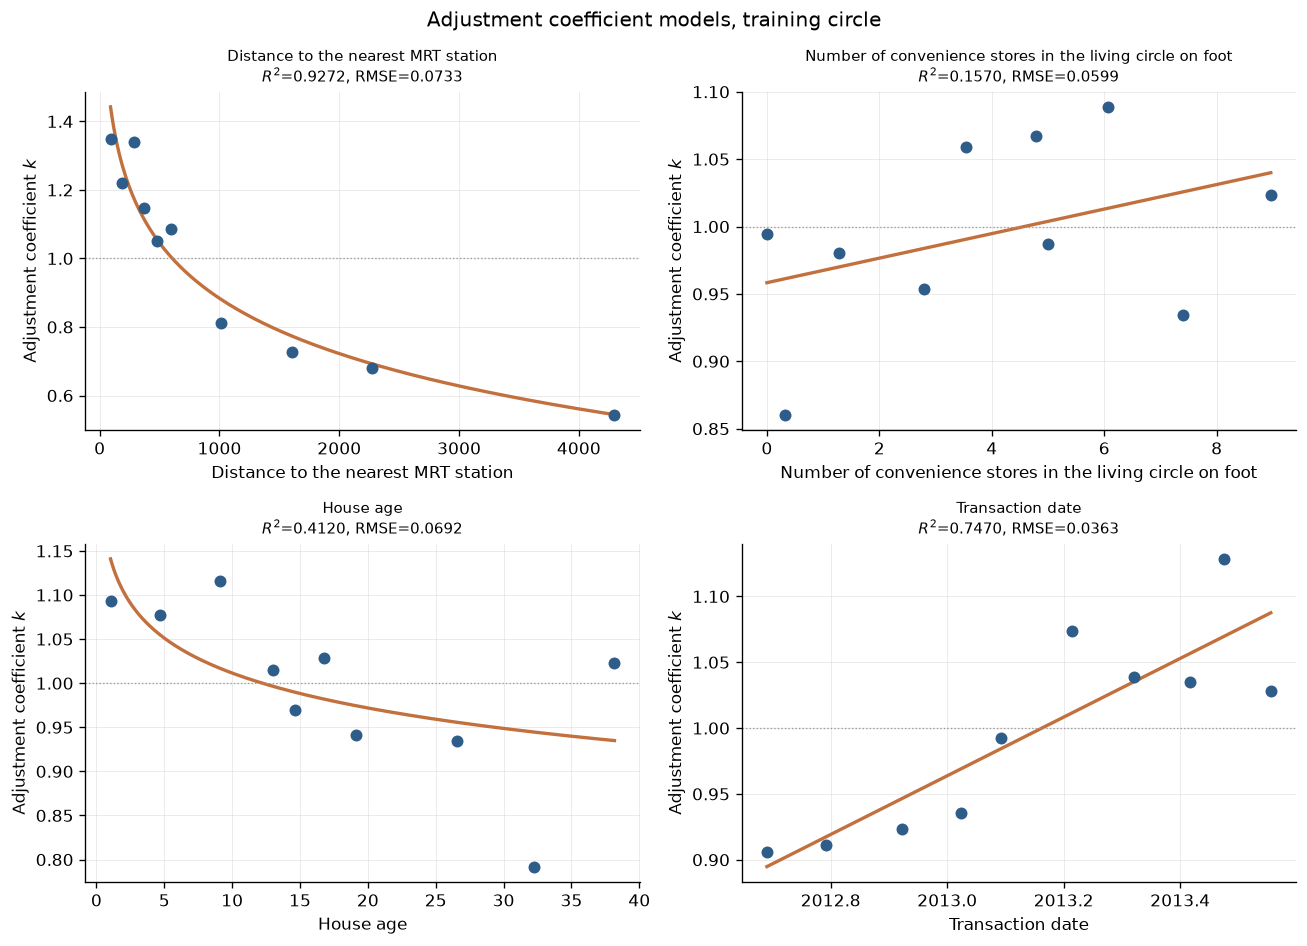

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, factor in zip(axes.ravel(), config.DECOMPOSITION_ORDER):
    plots.adjustment_curve(model, factor, ax=ax)
fig.suptitle("Adjustment coefficient models, training circle", fontsize=12)
fig.tight_layout()

Reading these as the paper does in Section 5.1:

* **MRT distance** — strongly decreasing, and the curvature is the point. Almost all of the effect is inside the first 500 m; beyond about 1 km extra distance costs little, because by then nobody is walking to the station anyway. A linear model would misprice both ends.
* **Convenience stores** — gently increasing. Each extra store in the walking circle adds about 1%.
* **House age** — decreasing, and again curved: depreciation is fastest in the first years.
* **Transaction date** — increasing, which over June 2012 to May 2013 is Sindian's price boom, the market trend rather than a property feature.

Every sign is the one the paper reports, and each is the sign economic reasoning predicts.

## 4. What the decomposition is worth on its own

Multiplying the coefficients back together gives a **multiplicative hedonic model**, $\bar{Y}\prod_i \hat{k}_i$. That is not the paper's approach — it has no comparative cases in it — but it is the right baseline for notebook 03, because it isolates how much the case-based comparison step adds over the coefficient models alone.

In [9]:
direct = model.predict_price(test)
baseline = metrics.evaluate(test[config.TARGET], direct, df[config.TARGET].mean())
pd.Series(baseline).to_frame("decomposition model only").round(4)

,decomposition model only
20% error hit rate,76.0870
10% error hit rate,52.8986
R2 (1-SSE/SST),0.6792
R2 (corr^2),0.6920
RMSE,7.3312
MAE,4.9643
MAPE,16.7898
Avg. house price,37.9802
RMSE/Avg. house price,0.1930


<Axes: title={'center': 'Decomposition model on the test set'}, xlabel='Actual price per unit area', ylabel='Predicted price per unit area'>

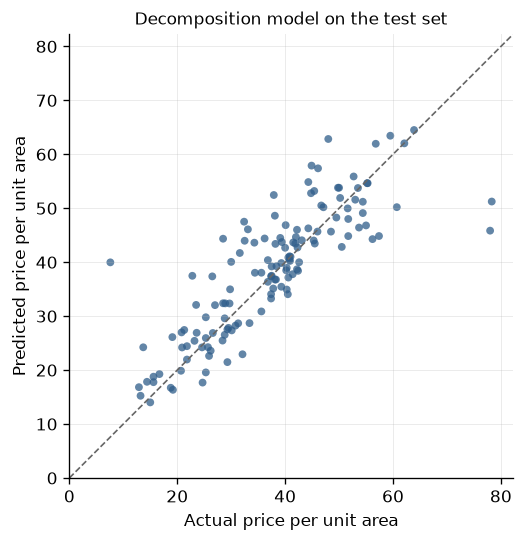

In [10]:
fig, ax = plt.subplots(figsize=(4.8, 4.8))
plots.actual_vs_predicted(test[config.TARGET], direct, ax=ax,
                          title="Decomposition model on the test set")

Keep this RMSE in mind: notebook 03 shows the full approach has to beat it to justify the extra machinery.